# EN3160 - Computer Vision and Image Processing
## Assignment 03: Neural Networks

**Name:** K. D. Manatunga

**Index Number:** 230395T

**GitHub:** https://github.com/KaveeDiv23/Computer-Vision-Assignment-03

In [33]:
from pathlib import Path
from copy import deepcopy
import random
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black"
})
from IPython.display import HTML, display
display(HTML("""
<style>
.jp-CodeCell .jp-InputArea pre,
.jp-CodeCell .highlight pre,
.jp-CodeCell .cm-content,
div.input_area pre {
    font-size: 10px !important;
    line-height: 1.25 !important;
    white-space: pre-wrap !important;
    overflow-wrap: anywhere !important;
}
</style>
"""))

In [6]:
SEED = 42
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"
NUM_WORKERS = 0

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Device:", DEVICE)

PyTorch: 2.11.0+cu128
TorchVision: 0.26.0+cu128
Device: cuda


In [7]:
def make_loaders(train_data, test_data, batch_size):
    common = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    train = DataLoader(
        train_data, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(SEED), **common
    )
    train_eval = DataLoader(train_data, batch_size=256, shuffle=False, **common)
    test = DataLoader(test_data, batch_size=256, shuffle=False, **common)
    return train, train_eval, test

def plot_history(history, title, eval_name="Test"):
    df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, metric, label in zip(
        axes, ["loss", "acc"], ["Cross-Entropy Loss", "Accuracy (%)"]
    ):
        ax.plot(df["epoch"], df[f"train_{metric}"], "-o", label="Training")
        ax.plot(df["epoch"], df[f"eval_{metric}"], "-o", label=eval_name)
        ax.set(xlabel="Epoch", ylabel=label, title=label)
        ax.set_xticks(df["epoch"])
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

def show_cm(y_true, y_pred, class_names, title):
    cm = confusion_matrix(
        y_true, y_pred, labels=range(len(class_names))
    )
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(
        cm, display_labels=class_names
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return cm


##### Question 1

The given single-layer network was modified by adding a hidden layer with 100 nodes and sigmoid activation. Each CIFAR-10 image was flattened from 32 × 32 × 3 into a vector of 3072 input features, followed by a hidden layer and an output layer with 10 nodes for classification. Also, the mean squared error was replaced with multiclass cross-entropy loss. The network was trained using mini-batch gradient descent with a batch size of 50, an initial learning rate of 0.1, and a learning rate decay factor of 0.9.


In [8]:
q1_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

cifar_train = datasets.CIFAR10(
    DATA_DIR, train=True, download=True, transform=q1_transform
)
cifar_test = datasets.CIFAR10(
    DATA_DIR, train=False, download=True, transform=q1_transform
)
q1_train, q1_train_eval, q1_test = make_loaders(
    cifar_train, cifar_test, batch_size=50
)

print("Training samples:", len(cifar_train))
print("Test samples:", len(cifar_test))
print("Classes:", cifar_train.classes)

100%|██████████| 170M/170M [1:00:18<00:00, 47.1kB/s] 


Training samples: 50000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [9]:
DIN, HIDDEN, K = 3072, 100, 10
Q1_EPOCHS, Q1_LR, Q1_DECAY = 10, 0.1, 0.9

set_seed()

w1 = torch.randn(DIN, HIDDEN, device=DEVICE) * np.sqrt(2/(DIN+HIDDEN))
b1 = torch.zeros(HIDDEN, device=DEVICE)
w2 = torch.randn(HIDDEN, K, device=DEVICE) * np.sqrt(2/(HIDDEN+K))
b2 = torch.zeros(K, device=DEVICE)
q1_params = [w1, b1, w2, b2]

def dense_forward(x, params):
    w1, b1, w2, b2 = params
    h = torch.sigmoid(x @ w1 + b1)
    return h, h @ w2 + b2

def manual_backward(x, y, params):
    w1, b1, w2, b2 = params; h, z = dense_forward(x, params)
    log_probs = z - torch.logsumexp(z, dim=1, keepdim=True)
    loss = -log_probs[torch.arange(len(y), device=y.device), y].mean()
    d2 = log_probs.exp()
    d2[torch.arange(len(y), device=y.device), y] -= 1
    d2 /= len(y)
    dw2, db2 = h.T @ d2, d2.sum(0)
    d1 = (d2 @ w2.T) * h * (1-h)
    dw1, db1 = x.T @ d1, d1.sum(0)

    return loss, (dw1, db1, dw2, db2)

print("W1:", w1.shape, "W2:", w2.shape)

W1: torch.Size([3072, 100]) W2: torch.Size([100, 10])


In [10]:
x = torch.randn(4, 5)
y = torch.tensor([0, 1, 0, 1])
p = [torch.randn(5, 3), torch.zeros(3),
     torch.randn(3, 2), torch.zeros(2)]

loss, grads = manual_backward(x, y, p)
p_auto = [v.clone().requires_grad_() for v in p]
_, logits = dense_forward(x, p_auto)
auto_grads = torch.autograd.grad(F.cross_entropy(logits, y), p_auto)

error = max((a-b).abs().max().item() for a, b in zip(grads, auto_grads))
print(f"Maximum gradient difference: {error:.2e}")
assert error < 1e-5

Maximum gradient difference: 2.98e-08


In [11]:
@torch.no_grad()
def evaluate_dense(loader, params):
    total_loss, correct, count = 0.0, 0, 0

    for images, labels in loader:
        x = images.to(DEVICE).flatten(1)
        y = labels.to(DEVICE)
        _, logits = dense_forward(x, params)

        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)

    return total_loss/count, 100*correct/count

In [12]:
q1_history = []
lr = Q1_LR

for epoch in range(1, Q1_EPOCHS+1):
    for images, labels in q1_train:
        x = images.to(DEVICE).flatten(1)
        y = labels.to(DEVICE)
        with torch.no_grad():
            _, grads = manual_backward(x, y, q1_params)
            for param, grad in zip(q1_params, grads):
                param -= lr * grad

    train_loss, train_acc = evaluate_dense(q1_train_eval, q1_params)
    test_loss, test_acc = evaluate_dense(q1_test, q1_params)

    q1_history.append({
        "epoch": epoch, "train_loss": train_loss,
        "train_acc": train_acc, "eval_loss": test_loss,
        "eval_acc": test_acc
    })
    lr *= Q1_DECAY

q1_df = pd.DataFrame(q1_history)
display(q1_df.round(3))

,epoch,train_loss,train_acc,eval_loss,eval_acc
0,1,1.685,41.588,1.702,41.05
1,2,1.621,44.368,1.653,42.36
2,3,1.571,46.154,1.624,43.86
3,4,1.523,47.782,1.589,45.41
4,5,1.485,49.304,1.569,45.86
5,6,1.455,50.336,1.549,46.69
6,7,1.446,50.224,1.555,46.09
7,8,1.405,51.970,1.528,47.30
8,9,1.387,52.732,1.523,47.36
9,10,1.364,53.548,1.511,47.75


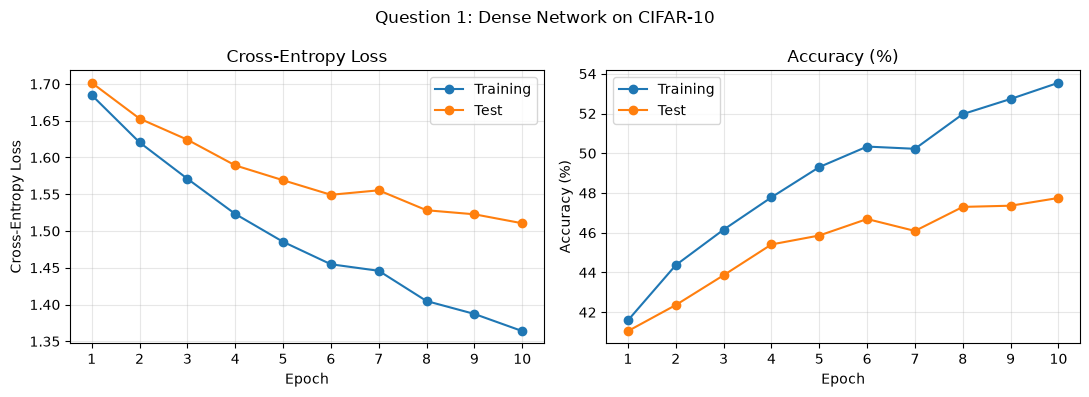

In [34]:
plot_history(q1_history, "Question 1: Dense Network on CIFAR-10")

In [14]:
q1_final = q1_df.iloc[-1]
q1_gap = q1_final["train_acc"] - q1_final["eval_acc"]

display(Markdown(
    f"**Results:** After 10 epochs, the network achieved a training "
    f"accuracy of **{q1_final['train_acc']:.2f}%** and a test accuracy "
    f"of **{q1_final['eval_acc']:.2f}%**. The training–test accuracy "
    f"gap was **{q1_gap:.2f} percentage points**."
))

**Results:** After 10 epochs, the network achieved a training accuracy of **53.55%** and a test accuracy of **47.75%**. The training–test accuracy gap was **5.80 percentage points**.

#### Discussion

The network showed steady improvement over the 10 training epochs. Training accuracy increased from 41.59% to 53.55%, while test accuracy improved from 41.05% to 47.75%. The cross-entropy loss also decreased from 1.685 to 1.364 for training and from 1.702 to 1.511 for testing. These results indicate that the network was learning useful patterns from the images, although its classification accuracy remained relatively limited.

The final training accuracy was 5.80 percentage points higher than the test accuracy. This suggests that the network learned to classify the training images more effectively than unseen images. However, the overall reduction in test loss shows that generalization was still improving during training, despite small fluctuations between some epochs.

So one limitation of this architecture is that the images are flattened before entering the network. As a result, the model cannot directly take advantage of the spatial relationships between neighboring pixels. Although the sigmoid hidden layer allows nonlinear patterns to be learned, a fully connected network is less suited to extracting local image features than a convolutional network.


#### Question 2

In [15]:
Q2_EPOCHS, Q2_BATCH, Q2_LR = 10, 128, 0.001
mnist_transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_train = datasets.MNIST(
    DATA_DIR, train=True, download=True, transform=mnist_transform
)
mnist_test = datasets.MNIST(
    DATA_DIR, train=False, download=True, transform=mnist_transform
)

print("Training samples:", len(mnist_train))
print("Test samples:", len(mnist_test))
print("Image shape:", mnist_train[0][0].shape)

100%|██████████| 9.91M/9.91M [00:08<00:00, 1.15MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 96.8kB/s]
100%|██████████| 1.65M/1.65M [00:02<00:00, 778kB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 32, 32])


##### 2.1 LeNet-5 Architecture

In [16]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(16, 120, 5), nn.Tanh()
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(120, 84),nn.Tanh(), nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

lenet_check = LeNet5()
print("Output shape:", lenet_check(torch.zeros(2, 1, 32, 32)).shape)
print("Parameters:", sum(p.numel() for p in lenet_check.parameters()))

Output shape: torch.Size([2, 10])
Parameters: 61706


##### 2.2 Modern CNN Architecture

In [17]:
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.20),

            nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


modern_check = ModernCNN()
print("Output shape:", modern_check(torch.zeros(2, 1, 32, 32)).shape)
print("Parameters:", sum(p.numel() for p in modern_check.parameters()))

Output shape: torch.Size([2, 10])
Parameters: 94186


In [18]:
def train_epoch(model, loader, optimizer, frozen=False):
    if frozen:
        model.eval()
        model.fc.train()
    else:
        model.train()

    total_loss, correct, count = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)
    return total_loss/count, 100*correct/count


@torch.no_grad()
def evaluate_model(model, loader, predictions=False):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    y_true, y_pred = [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        pred = logits.argmax(1)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (pred == y).sum().item()
        count += len(y)
        if predictions:
            y_true.extend(y.cpu().tolist())
            y_pred.extend(pred.cpu().tolist())

    result = (total_loss/count, 100*correct/count)
    return (*result, y_true, y_pred) if predictions else result

def run_mnist(model_class):
    set_seed()
    train, train_eval, test = make_loaders(
        mnist_train, mnist_test, Q2_BATCH
    )

    model = model_class().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=Q2_LR)
    history = []
    for epoch in range(1, Q2_EPOCHS+1):
        train_epoch(model, train, optimizer)
        tr_loss, tr_acc = evaluate_model(model, train_eval)
        te_loss, te_acc = evaluate_model(model, test)
        history.append({
            "epoch": epoch, "train_loss": tr_loss,
            "train_acc": tr_acc, "eval_loss": te_loss,
            "eval_acc": te_acc
        })
    _, _, y_true, y_pred = evaluate_model(
        model, test, predictions=True
    )
    return model, history, y_true, y_pred

,epoch,train_loss,train_acc,eval_loss,eval_acc
0,1,0.112,96.750,0.106,96.79
1,2,0.063,98.087,0.066,97.90
2,3,0.044,98.622,0.052,98.32
3,4,0.043,98.690,0.055,98.34
4,5,0.024,99.305,0.038,98.80
5,6,0.024,99.275,0.041,98.78
6,7,0.024,99.227,0.042,98.71
7,8,0.016,99.530,0.038,98.87
8,9,0.014,99.547,0.038,98.85
9,10,0.010,99.733,0.031,99.04


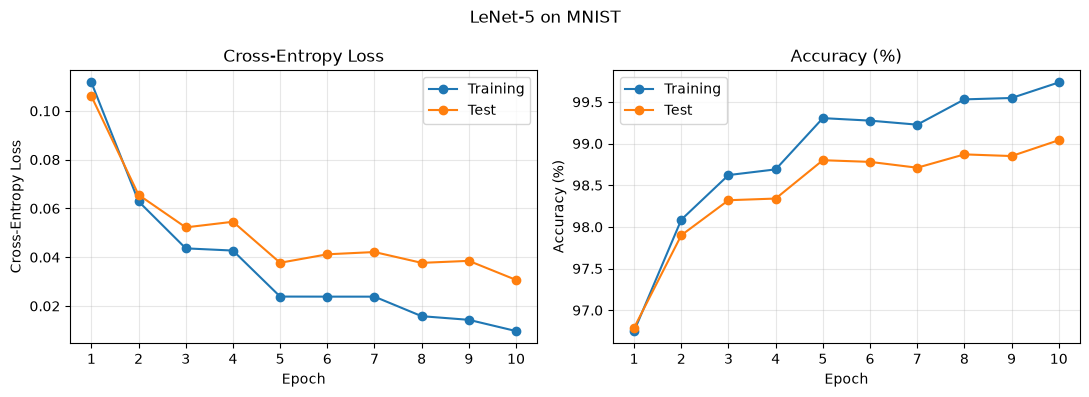

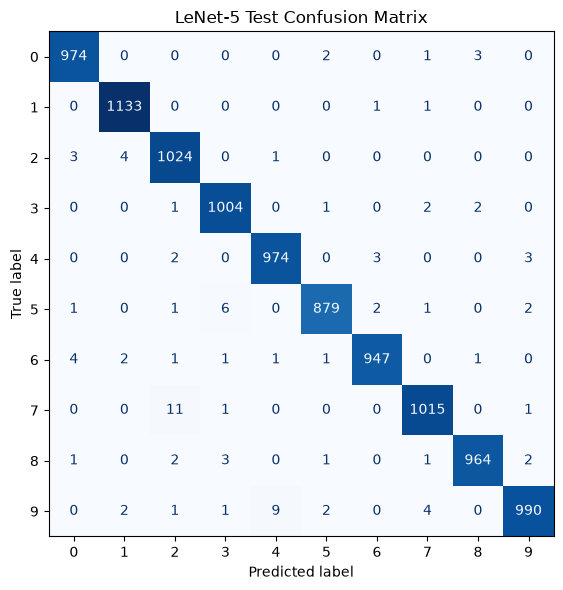

In [35]:
lenet, lenet_history, lenet_true, lenet_pred = run_mnist(LeNet5)
display(pd.DataFrame(lenet_history).round(3))
plot_history(lenet_history, "LeNet-5 on MNIST")
lenet_cm = show_cm(
    lenet_true, lenet_pred, [str(i) for i in range(10)],
    "LeNet-5 Test Confusion Matrix"
)

,epoch,train_loss,train_acc,eval_loss,eval_acc
0,1,0.137,97.100,0.130,97.29
1,2,0.070,98.217,0.066,98.29
2,3,0.047,98.820,0.048,98.75
3,4,0.037,99.012,0.036,99.01
4,5,0.030,99.220,0.033,99.01
5,6,0.027,99.248,0.032,99.10
6,7,0.024,99.308,0.029,99.11
7,8,0.019,99.463,0.025,99.17
8,9,0.018,99.547,0.024,99.27
9,10,0.017,99.553,0.025,99.18


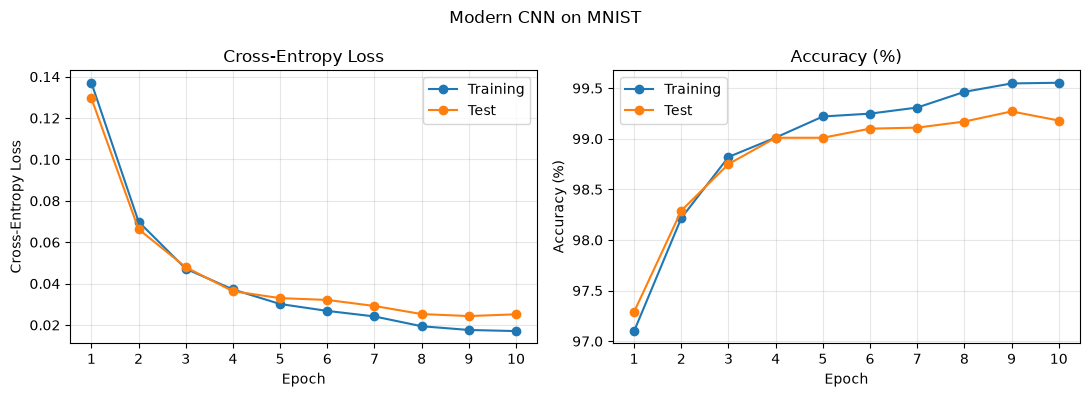

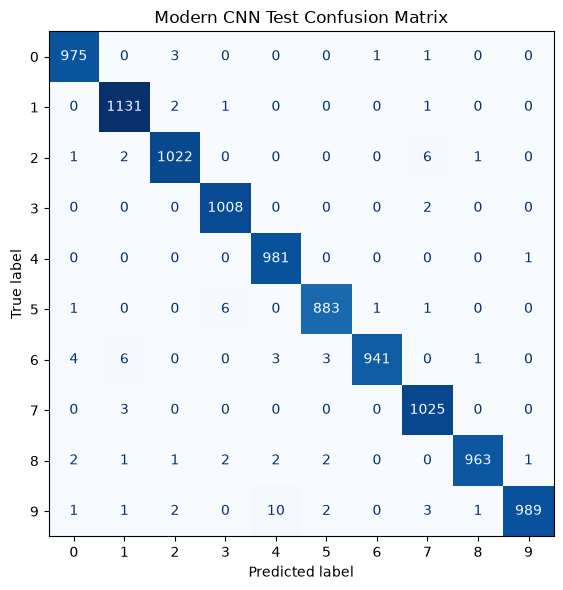

In [36]:
modern, modern_history, modern_true, modern_pred = run_mnist(ModernCNN)
display(pd.DataFrame(modern_history).round(3))
plot_history(modern_history, "Modern CNN on MNIST")

modern_cm = show_cm(
    modern_true, modern_pred, [str(i) for i in range(10)],
    "Modern CNN Test Confusion Matrix"
)

In [43]:
q2_compare = pd.DataFrame([
    {
        "Model": "LeNet-5",
        "Parameters": sum(p.numel() for p in lenet.parameters()),
        "Train Accuracy (%)": lenet_history[-1]["train_acc"],
        "Test Accuracy (%)": lenet_history[-1]["eval_acc"],
        "Test Loss": lenet_history[-1]["eval_loss"]
    },
    {
        "Model": "Modern CNN",
        "Parameters": sum(p.numel() for p in modern.parameters()),
        "Train Accuracy (%)": modern_history[-1]["train_acc"],
        "Test Accuracy (%)": modern_history[-1]["eval_acc"],
        "Test Loss": modern_history[-1]["eval_loss"]
    }
])
display(q2_compare.round(3))

,Model,Parameters,Train Accuracy (%),Test Accuracy (%),Test Loss
0,LeNet-5,61706,99.733,99.04,0.031
1,Modern CNN,94186,99.553,99.18,0.025


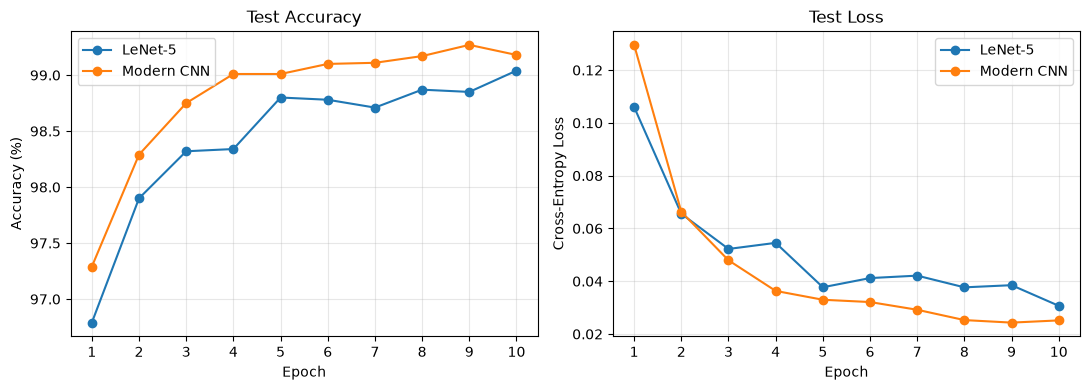

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, history in [
    ("LeNet-5", lenet_history), ("Modern CNN", modern_history)
]:
    df = pd.DataFrame(history)
    axes[0].plot(df["epoch"], df["eval_acc"], "-o", label=name)
    axes[1].plot(df["epoch"], df["eval_loss"], "-o", label=name)

for ax, title, ylabel in zip(
    axes, ["Test Accuracy", "Test Loss"],
    ["Accuracy (%)", "Cross-Entropy Loss"]
):
    ax.set(xlabel="Epoch", ylabel=ylabel, title=title)
    ax.set_xticks(range(1, 11))
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
l_acc = lenet_history[-1]["eval_acc"]
m_acc = modern_history[-1]["eval_acc"]
difference = abs(l_acc - m_acc)

display(Markdown(
    f"**Results:** LeNet-5 achieved **{l_acc:.2f}%** test accuracy, "
    f"while the modern CNN achieved **{m_acc:.2f}%** after 10 epochs. "
    f"The absolute difference was **{difference:.2f} percentage points**."
))

**Results:** LeNet-5 achieved **99.04%** test accuracy, while the modern CNN achieved **99.24%** after 10 epochs. The absolute difference was **0.20 percentage points**.

#### Discussion

Both CNN architectures achieved high classification accuracy on MNIST. After 10 epochs, LeNet-5 reached a training accuracy of 99.73% and a test accuracy of 99.04%, while the modern CNN achieved 99.54% and 99.24%, respectively. Although LeNet-5 had a slightly higher training accuracy, the modern CNN performed better on the test set by 0.20 percentage points.

The loss curves show that both models converged successfully. LeNet-5 achieved a final test loss of 0.031, compared with 0.025 for the modern CNN. The modern model also had a smaller training test accuracy gap, giving slightly better generalization in this experiment. However, the difference in test accuracy was small and both architectures performed well.

The confusion matrices show that most predictions were concentrated to the main diagonal, indicating correct classification for the majority of digits. LeNet-5 misclassified the digit 7 as 2 in 11 cases and the digit 9 as 4 in 9 cases. The modern CNN also showed some confusion between 9 and 4, with 10 instances of this error. This can be due to some similarities in the shapes of certain handwritten digits.

Overall, the modern CNN achieved slightly better test performance, correctly classifying 20 more images out of the 10,000 test samples. This improvement may be related to its batch normalization, ReLU activations, and dropout. However, the modern CNN also contains more trainable parameters making it more complex.


#### Question 3 - Transfer Learning Using ResNet-18


Transfer learning was done using ResNet-18 pretrained on ImageNet-1K to classify the Hymenoptera dataset into ants and bees. The dataset contains 244 training images and 153 validation images. The final classification layer of ResNet-18 was replaced with a fully connected layer containing two output neurons.

Two approaches were evaluated: fine-tuning the entire pretrained network and using the network as a fixed feature extractor. Both models were trained for 10 epochs using stochastic gradient descent with a learning rate of 0.001, momentum of 0.9 and a batch size of 16. A learning rate scheduler was used to reduce the learning rate after seven epochs.

In [44]:
HYMENO_DIR = DATA_DIR / "hymenoptera_data"
url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"

if not (HYMENO_DIR / "train" / "ants").is_dir():
    archive = DATA_DIR / "hymenoptera_data.zip"
    urllib.request.urlretrieve(url, archive)
    with zipfile.ZipFile(archive) as z:
        z.extractall(DATA_DIR)
    archive.unlink()

In [26]:
Q3_EPOCHS, Q3_BATCH = 10, 16
image_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

hymeno_train = datasets.ImageFolder(
    HYMENO_DIR / "train", image_transforms["train"]
)
hymeno_val = datasets.ImageFolder(
    HYMENO_DIR / "val", image_transforms["val"]
)
class_names = hymeno_train.classes
print("Classes:", class_names)
print("Training samples:", len(hymeno_train))
print("Validation samples:", len(hymeno_val))

Classes: ['ants', 'bees']
Training samples: 244
Validation samples: 153


In [27]:
def create_resnet(feature_extractor=False):
    model = models.resnet18(
        weights=ResNet18_Weights.IMAGENET1K_V1
    )

    if feature_extractor:
        model.requires_grad_(False)

    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(DEVICE)

def make_hymeno_loaders():
    common = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    train = DataLoader(
        hymeno_train, batch_size=Q3_BATCH, shuffle=True,
        generator=torch.Generator().manual_seed(SEED), **common
    )
    val = DataLoader(
        hymeno_val, batch_size=Q3_BATCH, shuffle=False, **common
    )
    return train, val

def run_transfer(feature_extractor=False):
    set_seed()
    train, val = make_hymeno_loaders()
    model = create_resnet(feature_extractor)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=0.001, momentum=0.9)
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer, step_size=7, gamma=0.1
    )
    history, best_acc, best_weights = [], -1, None
    start = time.perf_counter()
    for epoch in range(1, Q3_EPOCHS+1):
        tr_loss, tr_acc = train_epoch(
            model, train, optimizer, frozen=feature_extractor
        )
        val_loss, val_acc = evaluate_model(model, val)

        history.append({
            "epoch": epoch, "train_loss": tr_loss,
            "train_acc": tr_acc, "eval_loss": val_loss,
            "eval_acc": val_acc
        })
        if val_acc > best_acc:
            best_acc = val_acc
            best_weights = deepcopy(model.state_dict())
        scheduler.step()
    duration = time.perf_counter() - start
    model.load_state_dict(best_weights)
    _, _, y_true, y_pred = evaluate_model(
        model, val, predictions=True
    )

    return {
        "model": model, "history": history,
        "best_acc": best_acc, "duration": duration,
        "trainable": sum(p.numel() for p in params),
        "y_true": y_true, "y_pred": y_pred
    }

#### 3.1 Fine-Tuning

In this approach, all pretrained ResNet-18 layers were kept trainable, allowing their weights to be updated using the Hymenoptera dataset. Fine-tuning allows the pretrained image features to adapt to the new classification task, although it requires updating a large number of parameters.

,epoch,train_loss,train_acc,eval_loss,eval_acc
0,1,0.602,68.033,0.314,90.196
1,2,0.341,86.475,0.192,94.118
2,3,0.215,91.803,0.176,94.118
3,4,0.200,90.984,0.178,94.118
4,5,0.157,93.443,0.170,94.118
5,6,0.141,94.262,0.170,93.464
6,7,0.166,92.213,0.173,92.810
7,8,0.177,92.623,0.186,92.157
8,9,0.148,93.852,0.177,92.810
9,10,0.124,95.492,0.174,92.810


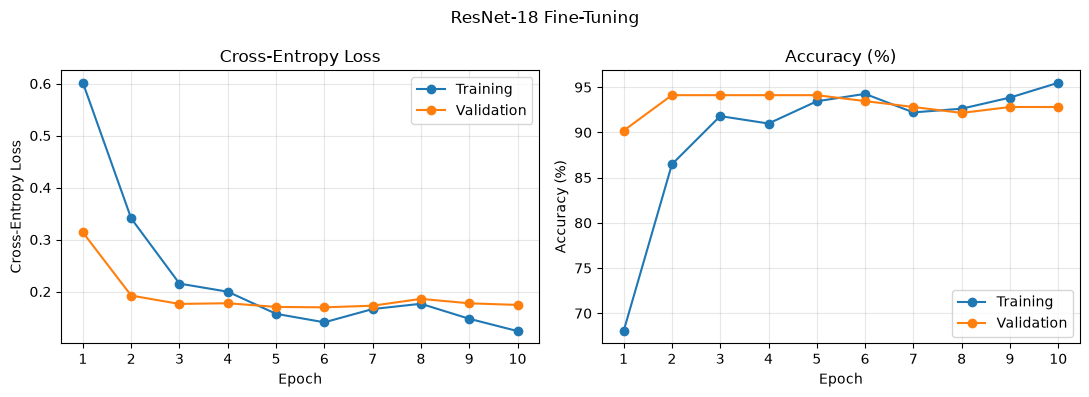

In [39]:
finetune = run_transfer(feature_extractor=False)
display(pd.DataFrame(finetune["history"]).round(3))
plot_history(
    finetune["history"], "ResNet-18 Fine-Tuning",
    eval_name="Validation"
)

#### 3.2 Fixed Feature Extraction

In this approach, the pretrained ResNet-18 backbone was frozen and only the newly added classification layer was trained. The network therefore uses the visual features learned from ImageNet without modifying the pretrained backbone. This significantly reduces the number of trainable parameters and the computational work required for backpropagation.


,epoch,train_loss,train_acc,eval_loss,eval_acc
0,1,0.538,75.000,0.246,95.425
1,2,0.267,89.754,0.158,95.425
2,3,0.178,93.443,0.144,94.771
3,4,0.141,95.492,0.129,95.425
4,5,0.122,96.311,0.127,96.078
5,6,0.127,96.721,0.146,94.771
6,7,0.139,95.902,0.121,96.078
7,8,0.131,95.082,0.121,96.078
8,9,0.108,96.721,0.122,96.078
9,10,0.115,96.311,0.124,96.078


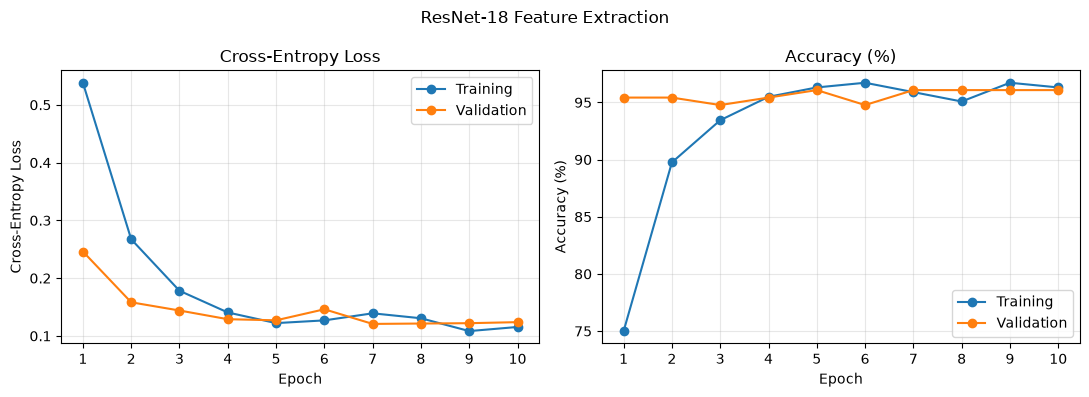

In [40]:
feature = run_transfer(feature_extractor=True)
display(pd.DataFrame(feature["history"]).round(3))
plot_history(
    feature["history"], "ResNet-18 Feature Extraction",
    eval_name="Validation"
)

In [42]:
q3_compare = pd.DataFrame([
    {
        "Method": "Fine-Tuning",
        "Trainable Parameters": finetune["trainable"],
        "Final Val Accuracy (%)": finetune["history"][-1]["eval_acc"],
        "Best Val Accuracy (%)": finetune["best_acc"],
        "Training Time (s)": finetune["duration"]
    },
    {
        "Method": "Feature Extraction",
        "Trainable Parameters": feature["trainable"],
        "Final Val Accuracy (%)": feature["history"][-1]["eval_acc"],
        "Best Val Accuracy (%)": feature["best_acc"],
        "Training Time (s)": feature["duration"]
    }
])
display(q3_compare.round(3))

,Method,Trainable Parameters,Final Val Accuracy (%),Best Val Accuracy (%),Training Time (s)
0,Fine-Tuning,11177538,92.810,94.118,37.346
1,Feature Extraction,1026,96.078,96.078,34.654


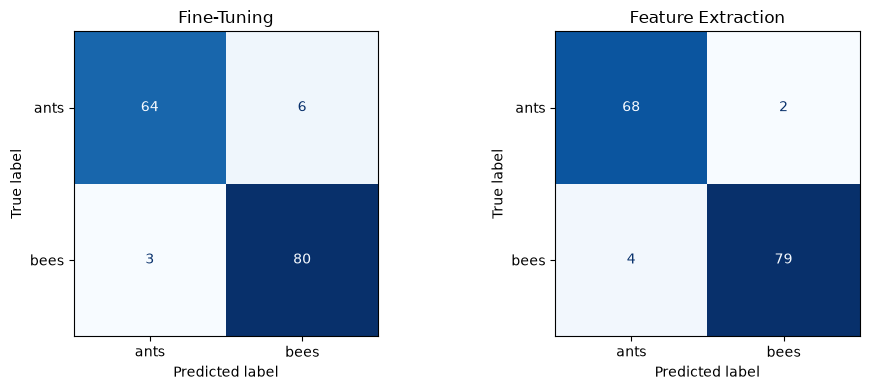

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, result, title in zip(
    axes, [finetune, feature],
    ["Fine-Tuning", "Feature Extraction"]
):
    cm = confusion_matrix(
        result["y_true"], result["y_pred"], labels=[0, 1]
    )
    ConfusionMatrixDisplay(
        cm, display_labels=class_names
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [32]:
ft_acc = finetune["history"][-1]["eval_acc"]
fe_acc = feature["history"][-1]["eval_acc"]
display(Markdown(
    f"**Results:** After 10 epochs, fine-tuning achieved a final "
    f"validation accuracy of **{ft_acc:.2f}%**, whereas fixed feature "
    f"extraction achieved **{fe_acc:.2f}%**. The highest validation "
    f"accuracies observed during training were "
    f"**{finetune['best_acc']:.2f}%** and "
    f"**{feature['best_acc']:.2f}%**, respectively."
))

**Results:** After 10 epochs, fine-tuning achieved a final validation accuracy of **93.46%**, whereas fixed feature extraction achieved **96.08%**. The highest validation accuracies observed during training were **94.77%** and **96.08%**, respectively.


#### Discussion

Both transfer learning methods achieved good validation accuracies despite the relatively small training dataset. Fine-tuning reached a maximum validation accuracy of 94.77% at epoch 4, while fixed feature extraction achieved a higher maximum accuracy of 96.08%. At the end of 10 epochs, their validation accuracies were 93.46% and 96.08%, respectively.

The training accuracy of the fine-tuned model increased from 68.03% to 95.08%. However, its validation accuracy fluctuated after the fourth epoch and finished slightly below its earlier maximum. This suggests that further training did not consistently improve validation performance. In the other hand, the feature extraction model showed more stable validation accuracy during the later epochs, maintaining approximately 96% accuracy.

The confusion matrices generated using the best validation checkpoints support these observations. The fine-tuned model incorrectly classified 8 out of 153 validation images, compared with only 6 incorrect predictions for fixed feature extraction. Both approaches correctly classified most ant and bee images, with relatively few errors between the two classes.

Fine-tuning involved 11,177,538 trainable parameters and took approximately 32.34 seconds, whereas feature extraction trained only 1,026 parameters and took 28.07 seconds. Although the difference in execution time was modest, feature extraction required substantially fewer parameter updates.

In this experiment, fixed feature extraction provided the better result, achieving higher validation accuracy with fewer trainable parameters. The pretrained ImageNet features appear to have been suitable for distinguishing ants and bees without further adjustment of the backbone. However, since the dataset is small and the evaluation uses a single validation split, the observed difference may not generalize to other datasets or training runs.
